# **Time-Use Habits in Finland. Statistical Analysis**

**Scenario.** A research organisation's Board commissioned a survey into how individuals and households in Finland spend their time, and wants a report answering four questions:

1. Who are the individuals in the sample?
2. How much time do households spend on average on each activity, per day?
3. Do living environment or day of week make a difference in time spent on any activity?
4. Which activities are associated with each other?

 This notebook is divided into 6 Steps:
- **Step 0:** Understanding the data
- **Step 1:** Data cleaning
- **Step 2:** Descriptive exploration and PCA *(Answers Question 1)*
- **Step 3:** Confidence intervals for household activity means *(Answers Question 2)*
- **Step 4:** Statistical testing of group differences *(Answers Question 3)*
- **Step 5:** Statistical association between activities *(Answers Question 4)*
- **Conclusions:** A short answer to each of the four questions

> **AI-use declaration:** Claude (Anthropic) was used as a preliminary roadmap to help organize our workflow step-by-step and as a double-check tool during the analysis. Additionally, it assisted in organizing and structuring the layout and formatting in Overleaf. However, all methodological choices, logic, and analytical decisions were entirely guided and driven by us. All quantitative results derive directly from our executed notebook, and this report was drafted with our own criteria.

---
# **STEP 0. Before touching the dataset**

**Objective of this step.** Read `habits.txt` carefully and understand, *before* writing any
code: what each variable means and what values it can take, what a row represents (an individual? a
household? a household on a given day?), which variables encode *living environment* and *day of
week*, and whether the documentation actually matches what is in the file.


In [3]:
# Libraries
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Display settings
RANDOM_STATE = 42
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 120)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100

DATA_PATH = "habits.data"
DOC_PATH = "habits.txt"

print("Setup complete.")


Setup complete.


### 0.1 Documentation from `habits.txt`

**Demographic variables** (one value per person, repeated across that person's diary days: sex, for example, is the same on both a person's working-day row and their weekend row).

| Variable | Meaning | Coded values |
|---|---|---|
| `kohde` | Household ID | integer |
| `jasen` | Member ID within household | integer |
| `pvknro` | Day of week (of that particular diary day) | 1 = working day, 2 = weekend |
| `sp` | Sex | 1 = male, 2 = female |
| `IKAL1` | Age group | documented as 1 = 10–14 … but the raw file does **not** actually follow this coding |
| `ASALUE` | Living environment | 1 = city, 2 = municipality, 3 = rural area |

**Activity variables**:

| Variable | Activity | Type |
|---|---|---|
| `A1` | Working | minutes |
| `A2` | Sleeping | minutes |
| `A3` | Reading | minutes |
| `A4` | Dining at a restaurant | minutes |
| `A5` | Visiting a library (past 12 months) | 1 = yes, 2 = no |

So `A1`–`A4` are **continuous time variables** and `A5` is **categorical (binary)**. Data type matters for EDA
and PCA. For example, Pearson/Spearman correlation only make sense for `A1`–`A4`, while `A5`
needs to be summarised as a proportion instead.


In [4]:
#  Load the raw data
df_raw = pd.read_csv(DATA_PATH, sep=";", dtype=str)

print("Shape:", df_raw.shape)
print()
print(df_raw.dtypes)
print()
df_raw.head(10)


Shape: (745, 11)

kohde     object
jasen     object
pvknro    object
sp        object
ASALUE    object
IKAL1     object
A1        object
A2        object
A3        object
A4        object
A5        object
dtype: object



,kohde,jasen,pvknro,sp,ASALUE,IKAL1,A1,A2,A3,A4,A5
0,50002,1,1,1,1.0,49,0,560,0,80,1.0
1,50002,1,2,1,1.0,49,380,450,10,0,1.0
2,50003,1,1,2,2.0,41,0,470,30,100,1.0
3,50003,1,2,2,2.0,41,0,550,0,0,1.0
4,50004,2,1,1,1.0,62,640,410,0,0,1.0
5,50004,2,2,1,1.0,62,0,550,72,108,1.0
6,50005,1,1,2,1.0,46,0,540,40,?,2.0
7,50005,1,2,2,1.0,46,0,550,52,108,2.0
8,50006,1,1,2,2.0,33,0,540,0,90,1.0
9,50006,1,2,2,2.0,33,0,530,62,0,1.0


### **0.2 What does a row represent? Checking the documentation against the actual file**
The documentation calls `kohde` a *household* ID and `jasen` a *member* ID. Before deciding how to
aggregate anything, we need to check:


1. How many people live in each household? If a household has more than one person, we'll need to sum their activity times to get the household total, since that's what's being asked. If each household has only 1 person, no summing is needed.

2. How many diary-day rows does each person have (max 2: one working
   day, one weekend day)? This matters for Step 4: comparing working
   day vs. weekend for the same person only works if that person has
   both days recorded.

In [5]:
# Structural checks:
members_per_household = df_raw.groupby("kohde")["jasen"].nunique()
rows_per_person = df_raw.groupby(["kohde", "jasen"]).size()

print("Number of distinct households (kohde):", df_raw["kohde"].nunique())

print("\n Q1: How many people live in each household?")
print(members_per_household.value_counts()) # 378 households have 1 person

print("\n Q2: How many diary-day rows does each person have?" ) # how many diary days each person registered, max 2
print(rows_per_person.value_counts()) # 367 people completed both days

print("\n day type (working day vs. weekend) counts") # working day vs. weekend counts
print(df_raw["pvknro"].value_counts())

Number of distinct households (kohde): 378

 Q1: How many people live in each household?
jasen
1    378
Name: count, dtype: int64

 Q2: How many diary-day rows does each person have?
2    367
1     11
Name: count, dtype: int64

 day type (working day vs. weekend) counts
pvknro
1    377
2    368
Name: count, dtype: int64


**Interpretation**: Every household (`kohde`) in this file has exactly one sampled member
(`jasen` is unique within each household), and each person contributes two diary-day rows, one
per value of `pvknro` (working day / weekend), with 11 people missing one of their two days. So summarizing:

- a row is one person, on one specific day
- "household" and "individual" mean the same thing here, since every household has just 1 person
- `pvknro` describes the day, so the same person shows up once as a working day and once as a weekend

We still write the code to sum by household and day, instead of assuming "1 row = 1 household". That way the code keeps working if a bigger version of this survey has households with 2 or more people.


### **Step 0 Recap**

- Each household in the file has one person, so "household" and "individual" are the same here.
- Each person has up to two diary rows: one working day and one weekend day. 367 people have both and 11 have only one.
- `A1` to `A4` are minutes, `A5` is a yes/no answer, and the age column does not follow the documentation (we deal with this in Step 1).

---
# **STEP 1. Data preparation**

**Objective of this step.** Turn the raw text file into a clean, correctly-typed table that can be
analysed: parse the inconsistently-formatted time variables, resolve the mismatch found in `IKAL1`,
quantify and treat missing values, check for implausible values, and give the categorical variables
readable labels. Every decision is justified.


### **1.1 Parsing the time variables (`A1` to `A4`)**

A first look at the raw values already shows a problem: the same column mixes **plain numbers**
(e.g. `"380"`) with **`HH:MM`-formatted strings** (e.g. `"01:20"`). Both need to end up as the same
unit (minutes) before they can be compared or summed:

- a value containing `":"` is a duration written as hours:minutes, so it is converted to `hours*60 + minutes`;
- a value without `":"` is already a plain minute count;
- the code `"?"` marks a missing observation and is converted to `NaN`.

We check the parser by looking at the resulting minute values: they should fall in a plausible daily range
(0 to 1440 minutes) for every activity, and no single day's total across `A1` to `A4` should exceed 1440
minutes (24 hours). The survey does not require activities to add up to the full day, so a total below 1440 minutes is normal. A total above 1440 is physically impossible and would point to a data error.

In [6]:
# Parse A1-A4 from mixed "plain minutes" / "HH:MM" text into a single minutes unit
def parse_time_to_minutes(value):
    """Convert a raw A1-A4 entry to minutes.

    Handles three cases found in the raw file:
      - '?'              -> missing (NaN)
      - 'HH:MM'           -> H*60 + M
      - a plain number    -> already minutes
    """
    if pd.isna(value):
        return np.nan
    value = str(value).strip()
    if value == "?":
        return np.nan
    if ":" in value:
        hours, minutes = value.split(":")
        return int(hours) * 60 + int(minutes)
    return float(value)


activity_raw_cols = {"A1": "working", "A2": "sleeping", "A3": "reading", "A4": "dining_restaurant"}

df = df_raw.copy()
for raw_col, nice_name in activity_raw_cols.items():
    df[f"{nice_name}_min"] = df[raw_col].apply(parse_time_to_minutes)

time_cols = [f"{name}_min" for name in activity_raw_cols.values()]

# Validation: plausible range + how many values came from each act.
for raw_col, nice_name in activity_raw_cols.items():
    col = f"{nice_name}_min"
    n_colon_format = df_raw[raw_col].astype(str).str.contains(":").sum()
    print(f"{nice_name:20s} range=[{df[col].min():.0f}, {df[col].max():.0f}] min   "
          f"n_missing={df[col].isna().sum():2d}   n_parsed_from_HH:MM={n_colon_format}")

daily_total = df[time_cols].sum(axis=1, skipna=True)
print()
print("Rows where A1+A2+A3+A4 exceeds 1440 minutes (should be none):", # careful if we had >1 person in the household
      int((daily_total > 1440).sum()))


working              range=[0, 1050] min   n_missing= 4   n_parsed_from_HH:MM=81
sleeping             range=[70, 900] min   n_missing= 8   n_parsed_from_HH:MM=80
reading              range=[0, 608] min   n_missing=12   n_parsed_from_HH:MM=82
dining_restaurant    range=[0, 240] min   n_missing= 9   n_parsed_from_HH:MM=82

Rows where A1+A2+A3+A4 exceeds 1440 minutes (should be none): 0


**Interpretation**: All four activities parse into a plausible 0 to 1440 minute range, and no single day's total exceeds 1440 minutes. Parsing looks correct and no impossible values were introduced.

**Note**: Here each row is one person on one day, so the 1440-minute check applies per person, not per household. A household with 2 or more people could have a combined total above 1440.

### **1.2 `IKAL1` (age): documentation does not match the data**

`habits.txt` documents `IKAL1` as a **9-level age-group code** (1 = 10-14 years ... 9 = 75+). The raw
values in `habits.data`, however, look like **actual ages in years**, not group codes.

In [7]:
# IKAL1: confirm the documentation mismatch
df["IKAL1"] = df["IKAL1"].astype(int)
print("IKAL1 raw range:", df["IKAL1"].min(), "-", df["IKAL1"].max())


IKAL1 raw range: 20 - 84


**Interpretation**: The values run from 20 to 84, so they are real ages in years and not group codes (codes would only go from 1 to 9).

We treat `IKAL1` as age in years and save it as `age_years`. From there we bin it into the age ranges used in the documentation (10-14, 15-19, 20-24, ... 75+) as `age_group`. The first two bands end up empty, because nobody in this sample is under 20.

In [8]:
# Build a readable age_group from the actual ages, using the documented band edges
age_bin_edges = [10, 15, 20, 25, 35, 45, 55, 65, 75, np.inf]
age_bin_labels = ["10-14", "15-19", "20-24", "25-34", "35-44",
                   "45-54", "55-64", "65-74", "75+"]

df["age_years"] = df["IKAL1"]
df["age_group"] = pd.cut(df["age_years"], bins=age_bin_edges, labels=age_bin_labels,
                          right=False, ordered=True)

print(df["age_group"].value_counts().sort_index())


age_group
10-14      0
15-19      0
20-24     24
25-34    113
35-44    124
45-54    162
55-64    183
65-74     86
75+       53
Name: count, dtype: int64


### **1.3 Recoding the remaining categorical variables**

`pvknro`, `sp` and `ASALUE` are already coded exactly as documented, so we only need to add readable labels.

In [9]:
# Recode pvknro, sp, ASALUE into readable categorical labels
df["pvknro"] = df["pvknro"].astype(int)
df["sp"] = df["sp"].astype(int)
df["ASALUE"] = df["ASALUE"].astype(float)


# int dtype can't hold NaN, so no .dropna() needed here
print("ASALUE missing:", df["ASALUE"].isna().sum(),
      f"({df['ASALUE'].isna().mean():.2%})")

# Data in the file looks coherent we can use asser directly to see if a condition is true
assert set(df["pvknro"].unique()) <= {1, 2}, "Unexpected pvknro code found"
assert set(df["sp"].unique()) <= {1, 2}, "Unexpected sp code found"
assert set(df["ASALUE"].dropna().unique()) <= {1.0, 2.0, 3.0}, "Unexpected ASALUE code found"

day_type_map = {1: "Working day", 2: "Weekend"}
sex_map = {1: "Male", 2: "Female"}
environment_map = {1.0: "City", 2.0: "Municipality", 3.0: "Rural area"}

df["day_type"] = df["pvknro"].map(day_type_map).astype("category")
df["sex"] = df["sp"].map(sex_map).astype("category")
df["living_environment"] = df["ASALUE"].map(environment_map).astype("category")

#Lets visualize new labels vs old

df[["pvknro", "day_type", "sp", "sex", "ASALUE", "living_environment"]].drop_duplicates().sort_values(
    ["pvknro", "sp", "ASALUE"]
)


ASALUE missing: 0 (0.00%)


,pvknro,day_type,sp,sex,ASALUE,living_environment
0,1,Working day,1,Male,1.0,City
13,1,Working day,1,Male,2.0,Municipality
37,1,Working day,1,Male,3.0,Rural area
6,1,Working day,2,Female,1.0,City
2,1,Working day,2,Female,2.0,Municipality
21,1,Working day,2,Female,3.0,Rural area
1,2,Weekend,1,Male,1.0,City
14,2,Weekend,1,Male,2.0,Municipality
38,2,Weekend,1,Male,3.0,Rural area
7,2,Weekend,2,Female,1.0,City


### **1.4 `A5` (library visits): another data-quality problem**

`A5` is documented as strictly binary (1 = yes, 2 = no). Checking the raw values shows several that do
not fit that scheme.

In [10]:
# A5: check which raw values do not match the documented 1/2 coding

a5_raw_values = df_raw["A5"].value_counts(dropna=False)
print(a5_raw_values)
print()
a5_non_conforming = df_raw.loc[~df_raw["A5"].isin(["1.0", "2.0"]) & (df_raw["A5"] != "?")]
print(f"Rows with an A5 value that is neither 1.0, 2.0 nor '?': {len(a5_non_conforming)}")
a5_non_conforming[["kohde", "A5"]]


A5
1.0      474
2.0      209
?         42
0.0       17
120.0      1
60.0       1
420.0      1
Name: count, dtype: int64

Rows with an A5 value that is neither 1.0, 2.0 nor '?': 20


,kohde,A5
70,50162,0.0
71,50162,0.0
124,50319,0.0
125,50319,0.0
190,50530,0.0
191,50530,0.0
196,50550,0.0
197,50550,0.0
272,50766,120.0
273,50766,60.0


**Interpretation**: Beyond the `?` missing markers, `A5` contains a handful of undocumented values: `0.0` in 17 rows,
and minute-like entries (`60.0`, `120.0`, `420.0`) in 3 more. Rather than guess what these mean, we
stick to the documentation: only `1.0` ("yes") and `2.0` ("no") are recoded, and everything else becomes
missing. That makes about 8% of the A5 rows missing (42 + 17 + 3 = 62 of 745 rows). This is a real cost, but it is safer
than inventing an interpretation for values the documentation does not define.

In [11]:
# A5: Everything else becomes NaN
library_map = {"1.0": "Yes", "2.0": "No"}
# .map() automatically turns any value not in the dictionary into NaN
df["library_visit"] = df_raw["A5"].map(library_map).astype("category")

print(df["library_visit"].value_counts(dropna=False)) # also counts NaN
print(f"Share of A5 treated as missing: {df['library_visit'].isna().mean():.2%}")


library_visit
Yes    474
No     209
NaN     62
Name: count, dtype: int64
Share of A5 treated as missing: 8.32%


In [12]:
# Assemble the cleaned table and rename columns in English

id_cols = ["kohde", "jasen"]
demo_cols = ["day_type", "sex", "age_years", "age_group", "living_environment"]
activity_cols = time_cols + ["library_visit"]

df_clean = df[id_cols + demo_cols + activity_cols].copy()
df_clean = df_clean.rename(columns={
    "kohde": "household_id",
    "jasen": "member_id",
    "working_min": "working",
    "sleeping_min": "sleeping",
    "reading_min": "reading",
    "dining_restaurant_min": "dining_restaurant",
})
time_cols_clean = ["working", "sleeping", "reading", "dining_restaurant"]

print(df_clean.shape)
df_clean.info()
df_clean.head()


(745, 12)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 745 entries, 0 to 744
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype   
---  ------              --------------  -----   
 0   household_id        745 non-null    object  
 1   member_id           745 non-null    object  
 2   day_type            745 non-null    category
 3   sex                 745 non-null    category
 4   age_years           745 non-null    int64   
 5   age_group           745 non-null    category
 6   living_environment  745 non-null    category
 7   working             741 non-null    float64 
 8   sleeping            737 non-null    float64 
 9   reading             733 non-null    float64 
 10  dining_restaurant   736 non-null    float64 
 11  library_visit       683 non-null    category
dtypes: category(5), float64(4), int64(1), object(2)
memory usage: 45.4+ KB


,household_id,member_id,day_type,sex,age_years,age_group,living_environment,working,sleeping,reading,dining_restaurant,library_visit
0,50002,1,Working day,Male,49,45-54,City,0.0,560.0,0.0,80.0,Yes
1,50002,1,Weekend,Male,49,45-54,City,380.0,450.0,10.0,0.0,Yes
2,50003,1,Working day,Female,41,35-44,Municipality,0.0,470.0,30.0,100.0,Yes
3,50003,1,Weekend,Female,41,35-44,Municipality,0.0,550.0,0.0,0.0,Yes
4,50004,2,Working day,Male,62,55-64,City,640.0,410.0,0.0,0.0,Yes


### **1.5 Missing values**

With the data fully prepared, we measure the exact amount of missing data in each column.

In [13]:
# Missing value summary
na_summary = pd.DataFrame({
    "n_missing": df_clean.isna().sum(),
    "%_missing": (df_clean.isna().mean() * 100).round(2),
})
na_summary


,n_missing,%_missing
household_id,0,0.00
member_id,0,0.00
day_type,0,0.00
sex,0,0.00
age_years,0,0.00
age_group,0,0.00
living_environment,0,0.00
working,4,0.54
sleeping,8,1.07
reading,12,1.61


### **1.6 Decision-making on missing values**

We first count how many rows miss at least one of the four time activities, and then decide how to treat each variable.

In [14]:
any_missing_activity = df_clean[time_cols_clean].isna().any(axis=1)
print(f"Rows with at least one missing value among the 4 time activities: "
      f"{any_missing_activity.sum()} ({any_missing_activity.mean():.1%})")


Rows with at least one missing value among the 4 time activities: 33 (4.4%)


**Interpretation**:

- `working`, `sleeping`, `reading` and `dining_restaurant`: each is missing in at most about 1.6% of rows on its own, and only 4.4% of rows miss at least one of the four. This is small, so dropping rows is fine for the analyses that need all four at once (correlation, PCA). For anything about a single activity, we keep all the valid data instead of throwing away a whole row because of a gap in another activity.

- `library_visit`: missing in about 8.3% of rows because of the invalid codes found earlier. We only need a simple yes/no proportion, so we leave these rows out of that calculation and keep them everywhere else.

- No demographic variable (`day_type`, `sex`, `age_group`, `living_environment`) has missing values, so no treatment is needed there.

### **1.7 Outliers and inconsistencies**

We already checked that no day's activities add up to more than 1440 minutes. Now we make sure the remaining values make sense: every time value must fall between 0 and 1440 minutes, the ages must be realistic for adults, and all categorical codes must match what is documented.

In [15]:

for col in time_cols_clean:
    out_of_range = ~df_clean[col].between(0, 1440) & df_clean[col].notna()
    print(f"{col:20s} out-of-[0,1440]-minute values: {int(out_of_range.sum()):2d}   "
          f"highest value seen: {df_clean[col].max():.0f} min")

age_out_of_range = ~df_clean["age_years"].between(15, 100)
print(f"\nAges outside a plausible [15, 100] range: {int(age_out_of_range.sum())}")
print(f"Actual age range in the sample: {df_clean['age_years'].min()}-{df_clean['age_years'].max()}")


working              out-of-[0,1440]-minute values:  0   highest value seen: 1050 min
sleeping             out-of-[0,1440]-minute values:  0   highest value seen: 900 min
reading              out-of-[0,1440]-minute values:  0   highest value seen: 608 min
dining_restaurant    out-of-[0,1440]-minute values:  0   highest value seen: 240 min

Ages outside a plausible [15, 100] range: 0
Actual age range in the sample: 20-84


**Interpretation**: No value falls outside the 0 to 1440 minute range, and all ages are realistic for adults. The highest
single values are working 1050 minutes (17.5 hours), sleeping 900 minutes (15 hours) and reading 608
minutes (10 hours). These are extreme, but they are physically possible for one day (for example a very long shift or a day off). We keep them instead of deleting or imputing them, because they look like real behaviour and not data entry errors.

We did not use a statistical rule such as the IQR or z-scores, because these variables have many genuine zeros (someone who simply did not work, read or eat out that day). A statistical outlier
rule would flag the large values as extreme even though the zeros are the most common valid answer for that
activity. A physical check (can this many minutes fit in a day?) is the more meaningful test
for activity-time data.

Together with the checks in Section 1.3, this confirms there are no other major errors besides the
two we already fixed: the mixed time formats in `A1` to `A4` and the undocumented codes in `A5`.

### **1.8 Household-level aggregation**

Each household has only one member (for example, a person reading for 60 minutes gives a household total of 60 minutes), so individual and household activity times are identical. We still group and sum by household and day, to keep the code ready for any household size and to prepare the table for Step 3.

In [16]:
# Household-day level aggregation (sum across household members)
df_household_day = (
    df_clean
    .groupby(["household_id", "day_type"], observed=True)[time_cols_clean]
    .sum(min_count=1)
    .reset_index()
)

print(df_household_day.shape)
df_household_day.head()


(745, 6)


,household_id,day_type,working,sleeping,reading,dining_restaurant
0,50002,Weekend,380.0,450.0,10.0,0.0
1,50002,Working day,0.0,560.0,0.0,80.0
2,50003,Weekend,0.0,550.0,0.0,0.0
3,50003,Working day,0.0,470.0,30.0,100.0
4,50004,Weekend,0.0,550.0,72.0,108.0


### **1.9 Unit of analysis and independence**

Each person appears in up to two rows (one working day, one weekend day). Many tests assume independent observations, so every test in this notebook is built so that a person is never counted twice as if they were two different people.

| Question | Unit | How we avoid counting a person twice |
|---|---|---|
| Average time per activity (3.1) | Person, within each day type | Each day type is analysed on its own, so every person appears once per estimate |
| Working day vs weekend (4.1.1) | Person | Paired test: each person is compared with themselves |
| Association between activities (5.1) | Person, within each day type | Analysed separately by day type, so there is one row per person. Averaging a person's two days would blur the daily time-use patterns |
| Living environment or library visit vs activities (4.1.2, 5.2) | Person | These are person-level variables, so each person's two days are combined into one weighted daily average (5/7 working day, 2/7 weekend) |

The exploratory parts (2.4 and 2.5) use all person-day rows and are descriptive only, so they have no p-values.

In [17]:
# Final cleaned tables produced
print("df_clean       (data per person):", df_clean.shape)
print("df_household_day (activity times per household):", df_household_day.shape)


df_clean       (data per person): (745, 12)
df_household_day (activity times per household): (745, 6)


### **Step 1 recap**

- We started from 745 raw rows with mixed time formats, an undocumented age coding and a few miscoded `A5` values.
- We now have two clean tables: `df_clean` (one row per person per diary day) and `df_household_day` (the same times at household-day level).
- Missing data is small: under 2% per activity and 8.3% for library visits. No impossible values remain.

---
# **STEP 2: Descriptive exploration and PCA**

**Objective of this step.** Characterise who is in the sample (question 1) and see how people spend their time across different activities. Then, we'll use a correlation matrix and a PCA to preview how activities relate to one another (Question 4), providing an overview before moving on to the statistical analysis in the following steps.

### **2.1 Characterisation of the individuals in the sample**

We summarise the demographic variables with frequency and proportion tables and bar
plots. Because each person contributes two rows (one per diary day), we compute these on the
**per-person** demographics (`sex`, `age_group`, `living_environment`; they do not change within a
person), so nobody is counted twice.

Note: `day_type` belongs to the *row* (working day or weekend), not to the *person*, so we only plot what describes the person.

In [18]:

person_demo = df_clean.drop_duplicates(subset=["household_id", "member_id"])[["sex", "age_group", "living_environment"]]

for col in ["sex", "age_group", "living_environment"]:
    freq = person_demo[col].value_counts().sort_index()
    prop = (person_demo[col].value_counts(normalize=True).sort_index() * 100).round(1)
    print(f"--- {col} ---")
    print(pd.DataFrame({"n": freq, "%": prop}))
    print()

print(f"Total individuals characterised: {person_demo.shape[0]}")


--- sex ---
          n     %
sex              
Female  196  51.9
Male    182  48.1

--- age_group ---
            n     %
age_group          
10-14       0   0.0
15-19       0   0.0
20-24      12   3.2
25-34      57  15.1
35-44      64  16.9
45-54      81  21.4
55-64      93  24.6
65-74      44  11.6
75+        27   7.1

--- living_environment ---
                      n     %
living_environment           
City                240  63.5
Municipality         58  15.3
Rural area           80  21.2

Total individuals characterised: 378


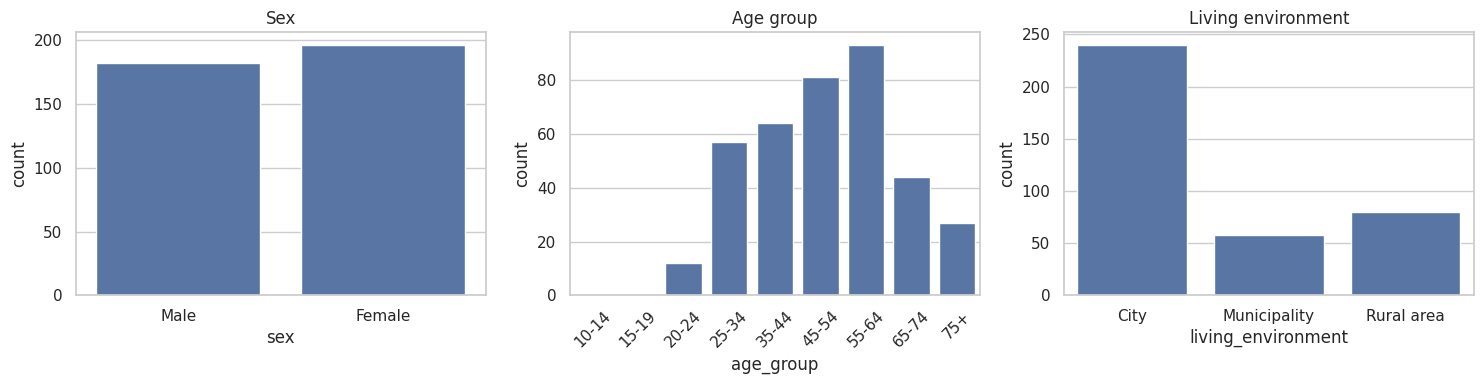

In [19]:
# Demographic bar plots
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.countplot(x="sex", data=person_demo, ax=axes[0], order=["Male", "Female"])
axes[0].set_title("Sex")

sns.countplot(x="age_group", data=person_demo, ax=axes[1],
              order=[c for c in person_demo["age_group"].cat.categories])
axes[1].set_title("Age group")
axes[1].tick_params(axis="x", rotation=45)

sns.countplot(x="living_environment", data=person_demo, ax=axes[2],
              order=["City", "Municipality", "Rural area"])
axes[2].set_title("Living environment")

plt.tight_layout()
plt.show()


**Interpretation**: The sample has 378 people. It is close to balanced by sex (51.9% women, 48.1% men). Everyone is an adult aged 20 to 84. The largest age groups are 55-64 (24.6%) and 45-54 (21.4%), and about 19% of people are 65 or older. Most people live in cities (63.5%), while 21.2% live in rural areas and 15.3% in municipalities.

### **2.2 Descriptive statistics of time spent per activity**

For the four continuous activities we report the mean, median and standard deviation (in minutes and,
for readability, in hours), then plot each variable's distribution.

In [20]:
#  Descriptive statistics table (minutes and hours)
desc_minutes = df_clean[time_cols_clean].describe().T[["mean", "50%", "std", "min", "max"]]
desc_minutes.columns = ["mean_min", "median_min", "sd_min", "min_min", "max_min"]
desc_minutes["mean_hours"] = (desc_minutes["mean_min"] / 60).round(2)
desc_minutes["median_hours"] = (desc_minutes["median_min"] / 60).round(2)
desc_minutes.round(1)


,mean_min,median_min,sd_min,min_min,max_min,mean_hours,median_hours
working,122.1,0.0,209.0,0.0,1050.0,2.0,0.0
sleeping,518.5,510.0,100.3,70.0,900.0,8.6,8.5
reading,48.0,30.0,68.1,0.0,608.0,0.8,0.5
dining_restaurant,48.6,0.0,58.7,0.0,240.0,0.8,0.0


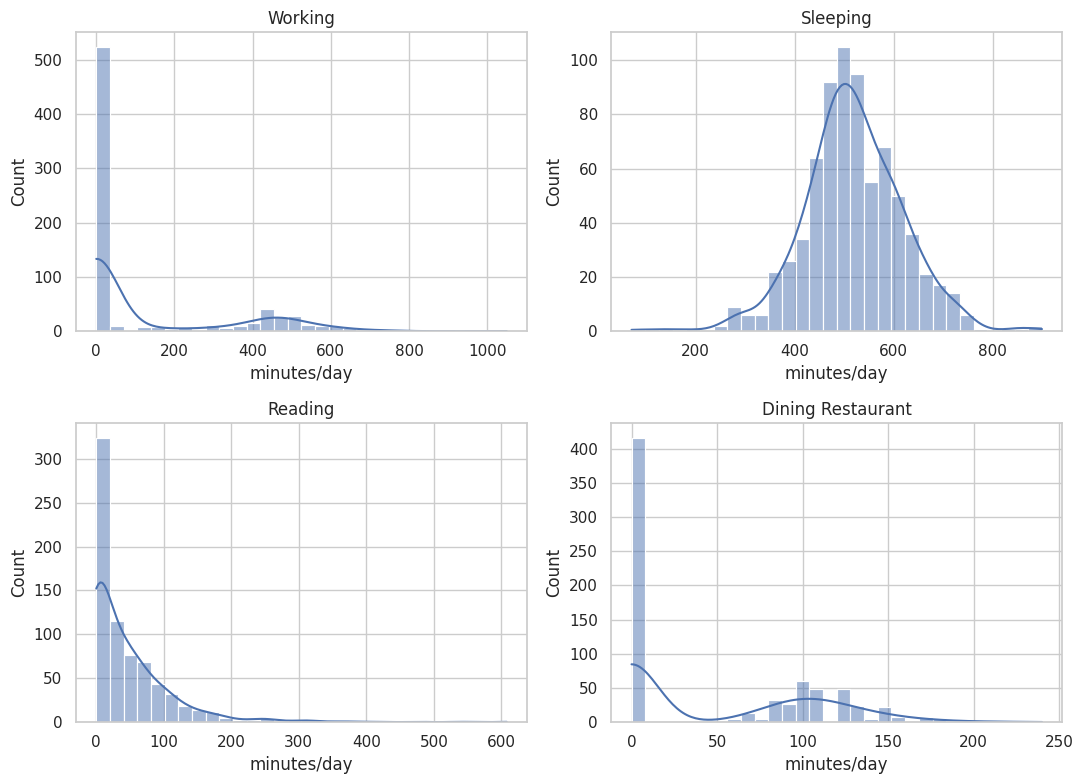

In [21]:
#  Histograms (num. feat) of each activity (distribution shape)
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, col in zip(axes.ravel(), time_cols_clean):
    sns.histplot(df_clean[col].dropna(), bins=30, kde=True, ax=ax, color="#4C72B0")
    ax.set_title(col.replace("_", " ").title())
    ax.set_xlabel("minutes/day")
plt.tight_layout()
plt.show()


**Interpretation**: `working` and `dining_restaurant` are strongly right-skewed with a large group at 0: on many days there is no work or no restaurant visit at all. For `working`, the median is 0 while the mean is about 122 minutes (2 hours), so a minority of long working days pulls the average up. `sleeping` looks roughly symmetric, with a mean of about 8.6 hours and a median of 8.5 hours. `reading` is also right-skewed with a spike at 0 (median 30 minutes, mean 48). This skew is why we prefer Spearman over Pearson for the correlation matrix below.

### **A first look: does time spent vary by group?**

Question 3 asks whether living environment or day of the week makes a difference. We do not test
that formally yet (that is Step 4), but the two boxplots below give a quick preview.

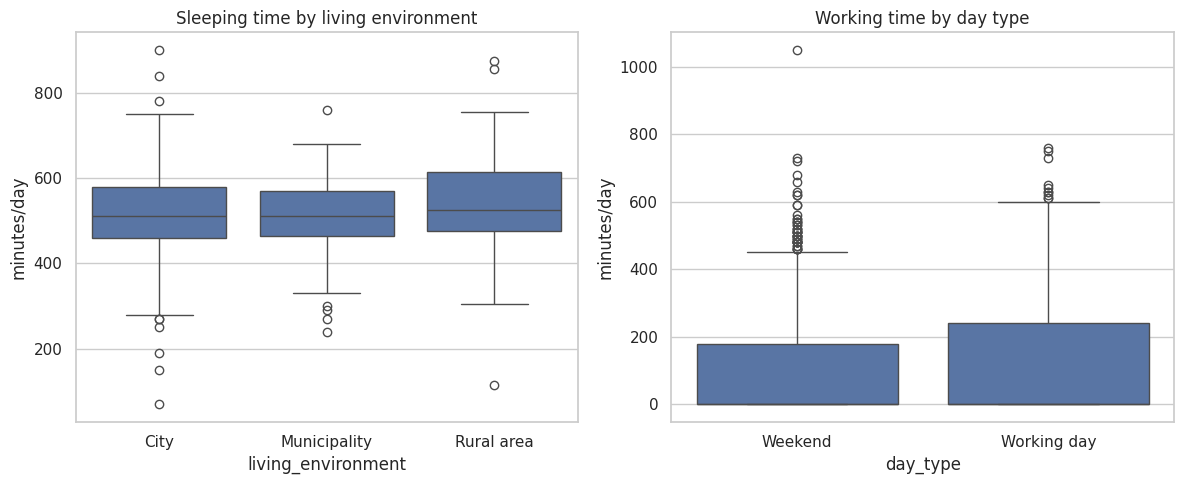

In [22]:
# We are interested in whether time spent differs by living environment
# or by day type -> box plot vis. + statis later
# Boxplots by group: living environment and day type

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(x="living_environment", y="sleeping", data=df_clean, ax=axes[0],
            order=["City", "Municipality", "Rural area"])
axes[0].set_title("Sleeping time by living environment")
axes[0].set_ylabel("minutes/day")

sns.boxplot(x="day_type", y="working", data=df_clean, ax=axes[1])
axes[1].set_title("Working time by day type")
axes[1].set_ylabel("minutes/day")

plt.tight_layout()
plt.show()


**Interpretation**: Sleeping time is fairly stable across living environments, centred around 8 to 9 hours, with only a few low and high outliers. Working time looks very similar on both day types: working days and weekends show roughly the same mean for working hours, and most people report 0 minutes on both.

This is a surprising result, because one would expect more work on working days. In our interpretation, it comes from the mixed make-up of the sample. It includes retirees, students, and self-employed people or shift workers, whose flexible or non-traditional schedules smooth out the differences between weekdays and weekends. The data has no occupation variable, so we cannot test this explanation directly.

### **2.3 Library visits (A5): descriptive analysis**

`library_visit` (A5) records whether the person visited a library at least once in the past 12 months, not on a given day. So it is summarised as a yes/no proportion, using a table with one row per person to avoid counting people twice across their diary days.

                 n
library_visit     
Yes            240
No             109
NaN             29

Proportion among non-missing responses (%):
library_visit
Yes    68.8
No     31.2
Name: proportion, dtype: float64


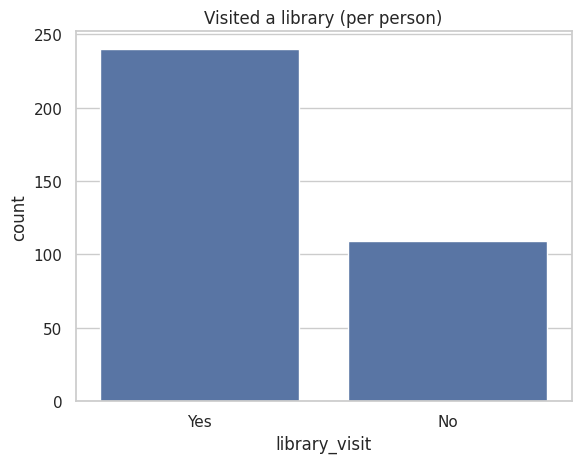

In [23]:
# Deduplicate to one row per person before summarising A5
person_a5 = (
    df_clean.groupby(["household_id", "member_id"], observed=True)["library_visit"]
    .apply(lambda x: x.dropna().iloc[0] if not x.dropna().empty else np.nan)
    .reset_index(name="library_visit")
)

lib_summary = person_a5["library_visit"].value_counts(dropna=False)
lib_prop = (person_a5["library_visit"].value_counts(normalize=True, dropna=True) * 100).round(1)
print(pd.DataFrame({"n": lib_summary}))
print()
print("Proportion among non-missing responses (%):")
print(lib_prop)

sns.countplot(x="library_visit", data=person_a5, order=["Yes", "No"], color="#4C72B0")
plt.title("Visited a library (per person)")
plt.show()


**Interpretation**: Among valid responses ($n=349$), about **68.8%** ($n=240$) report having visited a library in the past year, while **31.2%** ($n=109$) did not. A further **29 people** have no valid answer (`NaN`). Whether this behaviour differs across groups is tested in Step 4.

### **2.4 Correlation matrix between activities**

**Objective.** Give a first, direct answer to question 4 ("which activities are associated with
each other") and prepare the PCA below.

**Method choice.** The histograms in Section 2.2 showed clear right-skew (with spikes at zero) for
`working`, `reading` and, to a lesser extent, `dining_restaurant`. Pearson correlation assumes a roughly linear relationship and is sensitive to skew and outliers. Spearman's rank correlation is more suitable here: it ranks the minutes from lowest to highest, so it only needs a monotonic relationship and is robust to skewed data. We report the skewness to justify this choice.

Complete cases used for the correlation matrix: 712 of 745 rows

Skewness per activity:
working              1.37
sleeping            -0.10
reading              2.92
dining_restaurant    0.63
dtype: float64


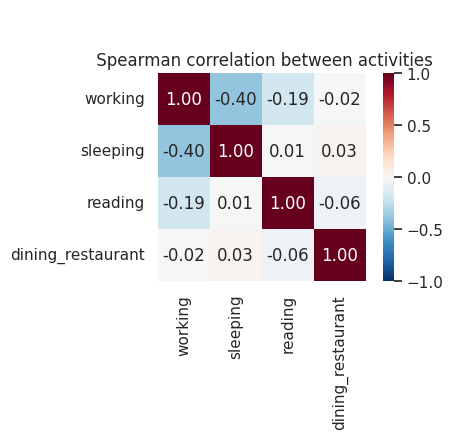

In [24]:
# Skewness check, then Spearman (primary) and Pearson (for comparison) correlations
corr_data = df_clean[time_cols_clean].dropna()
print(f"Complete cases used for the correlation matrix: {len(corr_data)} of {len(df_clean)} rows")
print()
print("Skewness per activity:")
print(corr_data.skew().round(2))

spearman_corr = corr_data.corr(method="spearman")

#  Correlation heatmap (Spearman)
plt.figure(figsize=(5.5, 4.5))
sns.heatmap(spearman_corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True)
plt.title("\n\n Spearman correlation between activities")
plt.tight_layout()
plt.show()


**Interpretation**: The clearest relationship is between `working` and `sleeping`: a moderate
negative correlation (-0.40). Days with more work tend to have less sleep. There is also a weak negative link between `working` and `reading` (about -0.19).

The other pairs are close to 0, so the four activities are only weakly related to each other. This already suggests that a PCA will not find one strong, easily summarised component. Correlation does not show cause, so we only say that these activities move together, not that one causes the other.

**Note**: This exploratory correlation uses 712 person-day rows (working days and weekends together). Since people contribute up to two rows, it shows overall patterns and not strictly independent subjects. The formal significance test is done in Step 5, split by day type so that there is one row per person.

### **2.5 Principal Component Analysis**

**Objective.** Check whether the four activity-time variables share a correlation structure that can be summarised in fewer dimensions.

**Standardisation.** `working`, `sleeping`, `reading` and `dining_restaurant` are all measured in the
same unit (minutes), but their variances differ a lot: sleeping varies in a narrow band compared
with working or dining out. PCA looks for directions of maximum variance, so a variable with a
bigger variance only because of its scale would dominate the components. Standardising each
variable to mean 0 and variance 1 removes that scale effect and lets every variable contribute
equally.

In [25]:
#  Prepare data for PCA
pca_data = df_clean[time_cols_clean].dropna()
X_scaled = StandardScaler().fit_transform(pca_data)
print(f"Observations used for PCA: {pca_data.shape[0]} (complete cases on the 4 activities)")

Observations used for PCA: 712 (complete cases on the 4 activities)


In [26]:
#  Fit PCA on all 4 standardised components, inspect eigenvalues / explained variance
pca = PCA(n_components=len(time_cols_clean), random_state=RANDOM_STATE)
pca.fit(X_scaled)

eigenvalues = pca.explained_variance_
explained_ratio = pca.explained_variance_ratio_
cum_explained = np.cumsum(explained_ratio)

pca_summary = pd.DataFrame({
    "eigenvalue": eigenvalues.round(3),
    "explained_variance_%": (explained_ratio * 100).round(1),
    "cumulative_%": (cum_explained * 100).round(1),
}, index=[f"PC{i+1}" for i in range(len(time_cols_clean))])
pca_summary


,eigenvalue,explained_variance_%,cumulative_%
PC1,1.420,35.4,35.4
PC2,1.082,27.0,62.5
PC3,0.960,24.0,86.4
PC4,0.544,13.6,100.0


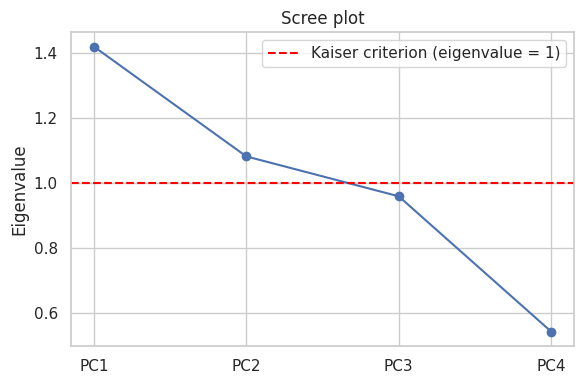

In [27]:
#  Scree plot
plt.figure(figsize=(6, 4))
components = np.arange(1, len(eigenvalues) + 1)
plt.plot(components, eigenvalues, marker="o")
plt.axhline(1, color="red", linestyle="--", label="Kaiser criterion (eigenvalue = 1)")
plt.xticks(components, [f"PC{i}" for i in components])
plt.ylabel("Eigenvalue")
plt.title("Scree plot")
plt.legend()
plt.tight_layout()
plt.show()


**Interpretation**: Only PC1 (eigenvalue 1.42) and PC2 (1.08) pass the Kaiser criterion (eigenvalue above 1), so we keep these two. The cut is not very sharp: PC2 is barely above 1 and PC3 (0.96) is just below it. Together the two components explain about 62.5% of the variance. This is only a moderate share, which means about 38% of the variation is not shown in a two-dimensional view.

In [28]:
#  Weights of each activity in the retained components (eigenvector coefficients from the PCA)
n_components_retained = 2
loadings = pd.DataFrame(
    pca.components_[:n_components_retained].T,
    index=time_cols_clean,
    columns=[f"PC{i+1}" for i in range(n_components_retained)],
)
loadings.round(3)


,PC1,PC2
working,0.718,-0.102
sleeping,-0.649,-0.318
reading,-0.237,0.758
dining_restaurant,-0.084,-0.561


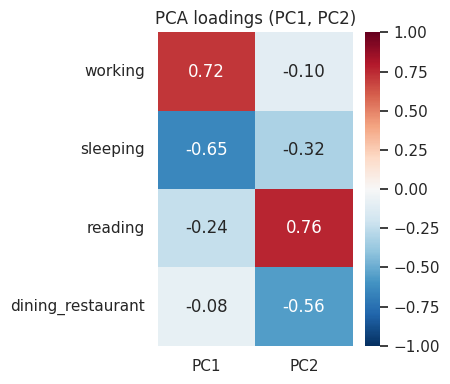

In [29]:
# Loadings heatmap
plt.figure(figsize=(4.5, 4))
sns.heatmap(loadings, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1)
plt.title("PCA loadings (PC1, PC2)")
plt.tight_layout()
plt.show()


**Interpretation**: The values in the table above are the weights of each activity in each component. PC1 works like a "work versus rest" axis: it contrasts `working` (+0.72) with `sleeping` (-0.65), so a high score means someone who works more and sleeps less. This is the main trade-off in the data. PC2 works more like a leisure axis: it contrasts `reading` (+0.76) with `dining_restaurant` (-0.56) and `sleeping` (-0.32), separating people who spend spare time reading from those who eat out.

The work-rest trade-off is the strongest pattern, and the second component picks up a weaker split between kinds of leisure time. The PCA uses all 712 person-day rows, so a person can appear twice. It is a descriptive summary, not a test.

### **Step 2 Recap**

- **Who is in the sample?** 378 adults aged 20 to 84, almost balanced by sex, and mostly living in cities.
- **How do people spend their time?** Work and dining out are skewed with many zeros. Sleep is about 8.6 hours a day.
- **Which activities go together?** Work and sleep have the clearest link (more work, less sleep). The other pairs are weak.
- **PCA:** Two components explain about 62.5% of the variance, which is only moderate.
- Step 2 is descriptive. The formal tests come in Steps 4 and 5.

---
# **STEP 3: Household Activity Means**

**Research Question:** *How much time do households spend on average on each activity, **per day**?*

### **3.1 Confidence intervals for continuous activity means (A1–A4)**


To answer this question, we calculate the sample mean and the 95% Confidence Intervals (CI) for each continuous activity. To see how routines change, these estimates are separated by day type (`Working day` vs. `Weekend`).

**Method choice:** To estimate the true population mean, we build 95% confidence intervals with the **t-distribution**, because the population variance is unknown and has to be estimated from the sample. A normality test is not needed here: with about 370 observations per day type, the Central Limit Theorem makes the sample mean approximately normal. This is a fair approximation even for skewed variables such as `working` and `dining_restaurant`.

**Independence:** Within each day type, every household appears once, so the observations are independent. The two day types come from the same people, but we build their intervals separately and do not compare them here (that is Step 4).

*(Note: While Step 3 estimates  average, where large samples make normality tests unnecessary via the Central Limit Theorem, Step 4 compares different groups, which requires checking data distributions to choose the correct statistical test).*

In [30]:
# The four time activities (A1 to A4)
activity_columns = ['working', 'sleeping', 'reading', 'dining_restaurant']

ci_results = []

# Each day type is analysed on its own: one row per household in each group
for day_type, subset in df_household_day.groupby('day_type', observed=True):
    for activity in activity_columns:
        if activity in subset.columns:
            data = subset[activity].dropna()
            mean = data.mean()
            n = len(data)
            se = stats.sem(data)

            # Calculate 95% Confidence Interval using the t-distribution
            h = se * stats.t.ppf((1 + 0.95) / 2., n - 1)
            ci_lower = mean - h
            ci_upper = mean + h

            ci_results.append({
                'day_type': day_type,
                'activity': activity,
                'mean_time': mean,
                'std_error': se,
                'ci_lower': ci_lower,
                'ci_upper': ci_upper,
                'sample_size': n
            })

df_ci_summary = pd.DataFrame(ci_results)
print("95% Confidence Intervals for Daily Activity Time by Household:")
display(df_ci_summary)

95% Confidence Intervals for Daily Activity Time by Household:


,day_type,activity,mean_time,std_error,ci_lower,ci_upper,sample_size
0,Weekend,working,122.076503,10.949811,100.543868,143.609137,366
1,Weekend,sleeping,521.304945,4.888879,511.690864,530.919027,364
2,Weekend,reading,51.444751,3.772775,44.025374,58.864129,362
3,Weekend,dining_restaurant,55.879121,3.351056,49.289199,62.469042,364
4,Working day,working,122.133333,10.784915,100.926662,143.340005,375
5,Working day,sleeping,515.857909,5.527714,504.988425,526.727392,373
6,Working day,reading,44.663073,3.329409,38.116136,51.210010,371
7,Working day,dining_restaurant,41.478495,2.705066,36.159309,46.797680,372


**Interpretation**: These 95% confidence intervals estimate the average daily time households spend on each activity. Sleep is the largest: about 516 minutes (8.6 hours) on working days and 521 minutes on weekends. Reading and dining out take about 45 to 56 minutes a day, and both are a little higher on weekends.

Working days and weekends show roughly the same mean for working hours (122.1 minutes on both, with an interval of about 100 to 143 minutes). This is surprising. In our interpretation, it comes from the mixed make-up of the sample: it includes retirees, students, and self-employed people or shift workers, whose flexible or non-traditional schedules smooth out the differences between weekdays and weekends. The data has no occupation variable, so we could not check this directly.

### **3.2 Complementary Analysis: Overall Daily Average (Weighted by Real Week)**

Section 3.1 gives the main breakdown by day type. As an extra view, we also compute one overall daily average. To reflect a real calendar week (5 working days and 2 weekend days), we combine the two means using the weights $5/7$ and $2/7$, instead of a simple 50/50 average that would give the weekend too much weight. This is a point estimate only, without a confidence interval.

In [31]:
# Added: weighted daily mean = (5/7) * working-day mean + (2/7) * weekend mean
weighted_rows = []
for activity in activity_columns:
    wd_mean = df_household_day.loc[df_household_day.day_type == "Working day", activity].mean()
    we_mean = df_household_day.loc[df_household_day.day_type == "Weekend", activity].mean()
    weighted_mean = (5/7) * wd_mean + (2/7) * we_mean
    weighted_rows.append({
        "activity": activity,
        "working_day_mean": wd_mean,
        "weekend_mean": we_mean,
        "weighted_daily_mean": weighted_mean,
    })

df_weighted = pd.DataFrame(weighted_rows)
print("Weighted daily average (5/7 working day + 2/7 weekend):")
display(df_weighted.round(1))


Weighted daily average (5/7 working day + 2/7 weekend):


,activity,working_day_mean,weekend_mean,weighted_daily_mean
0,working,122.1,122.1,122.1
1,sleeping,515.9,521.3,517.4
2,reading,44.7,51.4,46.6
3,dining_restaurant,41.5,55.9,45.6


### **3.3 Proportion and frequency summary for Activity 5 (`library_visit`)**

Activities A1 to A4 measure minutes per day, but Activity 5 (`library_visit`) is a yes/no variable that records whether the person visited a library at least once in the past 12 months (1 = yes, 2 = no). No average can be computed here, so we summarise it with frequencies and proportions.

Since `library_visit` is asked once per person, we reduce it to one row per person.

In [32]:
# deduplicate to person level
person_a5 = (
    df_clean.groupby(["household_id", "member_id"], observed=True)["library_visit"]
    .apply(lambda x: x.dropna().iloc[0] if not x.dropna().empty else np.nan)
    .reset_index(name="library_visit")
)

lib_counts = person_a5["library_visit"].value_counts(dropna=False)
lib_props = (person_a5["library_visit"].value_counts(normalize=True, dropna=True) * 100).round(1)

df_lib_summary = pd.DataFrame({
    'Frequency (n)': lib_counts,
    'Percentage (%)': [f"{lib_props.get(cat, 0)}%" if pd.notna(cat) else "Missing" for cat in lib_counts.index]
})

print("Summary for Activity 5 (Library Visits, per person):")
display(df_lib_summary)


Summary for Activity 5 (Library Visits, per person):


,Frequency (n),Percentage (%)
library_visit,,
Yes,240,68.8%
No,109,31.2%
NaN,29,Missing


**Interpretation**:

- Most people report having visited a library in the past 12 months (about **68.8%** "Yes"), while about **31.2%** say "No".
- **29 people** have no valid answer (`NaN`), and the percentages are calculated without them.

### **Step 3 Recap**

- **Time activities (A1 to A4):** We estimated the average daily time and a 95% confidence interval for each activity, separately for working days and weekends.
- **Overall daily mean:** We combined the two day types with weights 5/7 and 2/7 to get one average day.
- **Library visits (A5):** About 69% of people with a valid answer visited a library in the past year.
- **Working time:** The mean is about 122 minutes on both day types.

---
# **Step 4: Statistical Testing of Group Differences**

**Research Question:** *Do the type of day or living environment make a difference in the time spent on any activity?*


**Note on multiple testing**

In this step we run several tests at once (one for each activity). The more tests we run, the more likely it is that one of them looks significant by pure chance. To control this, we adjust the p-values with the **False Discovery Rate (FDR)** method (Benjamini-Hochberg). We apply it to each group of tests that answer the same question, and we base every decision on the adjusted p-value (`p_fdr`).

### **4.1.1 Day of the Week Effect**

The same people are measured on a working day and on a weekend day, so the two samples are dependent and we use a paired design: each person is compared with themselves. People with only one of the two days (11 people) cannot be paired and are left out of this test.

We first test normality with the Shapiro-Wilk test on the paired differences ($d = \text{Working day} - \text{Weekend}$), supported by distribution plots. If $p \ge 0.05$ we use the paired t-test, and if $p < 0.05$ we use the non-parametric Wilcoxon signed-rank test. To account for multiple testing across the 4 activities, we adjust the p-values with FDR.

* **Definition of $H_0$:** For a given activity, the type of day makes no difference to the time spent (working day and weekend are the same).
* **Decision Rule:** If the FDR-adjusted $p$-value is less than $0.05$ (`significant_fdr == True`), we reject $H_0$ for that activity. If $p_{fdr} \ge 0.05$ (`False`), we fail to reject $H_0$.

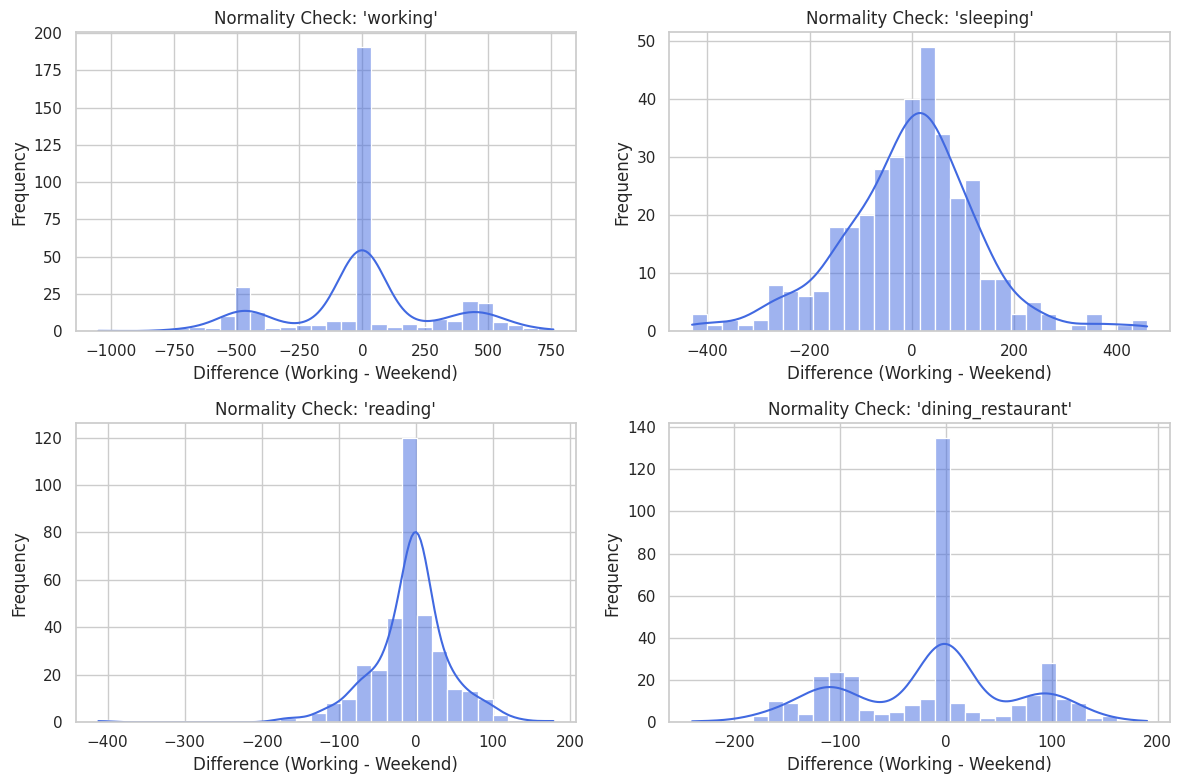

Paired Test Results (Day of Week):


,activity,normality_p_value,test_applied,statistic,p_value,p_fdr,significant_fdr
0,working,6.952613e-16,Wilcoxon signed-rank,7415.5,0.671584,0.710057,False
1,sleeping,1.900683e-05,Wilcoxon signed-rank,28646.5,0.710057,0.710057,False
2,reading,9.692307e-15,Wilcoxon signed-rank,16094.5,0.010859,0.021719,True
3,dining_restaurant,1.433411e-10,Wilcoxon signed-rank,10161.0,0.000191,0.000762,True


In [33]:
# Day of the Week Effect
paired_results = []
# 'id' does not exist, so the first column of df_clean (household_id) is used. Each household has one person, so it works as the person ID
id_col = 'id' if 'id' in df_clean.columns else df_clean.columns[0]


fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()

for idx, activity in enumerate(activity_columns):
    ax = axes[idx]
    if activity in df_clean.columns:
        pivoted = df_clean.pivot(index=id_col, columns='day_type', values=activity).dropna()

        if 'Working day' in pivoted.columns and 'Weekend' in pivoted.columns:
            diff = pivoted['Working day'] - pivoted['Weekend']

            #plot
            sns.histplot(diff, ax=ax, kde=True, color='royalblue', bins=30)
            ax.set_title(f"Normality Check: '{activity}'")
            ax.set_xlabel("Difference (Working - Weekend)")
            ax.set_ylabel("Frequency")

            # Shapiro-Wilk normality test on differences
            shapiro_stat, shapiro_p = stats.shapiro(diff)
            is_normal = shapiro_p > 0.05

            # Select test based on normality result
            if is_normal:
                stat, p_val = stats.ttest_rel(pivoted['Working day'], pivoted['Weekend'])
                test_used = "Paired t-test"
            else:
                stat, p_val = stats.wilcoxon(pivoted['Working day'], pivoted['Weekend'])
                test_used = "Wilcoxon signed-rank"

            paired_results.append({
                'activity': activity,
                'normality_p_value': shapiro_p,
                'test_applied': test_used,
                'statistic': stat,
                'p_value': p_val,
            })

plt.tight_layout()
plt.show()

df_paired_summary = pd.DataFrame(paired_results)

df_paired_summary["p_fdr"] = stats.false_discovery_control(df_paired_summary["p_value"])
df_paired_summary["significant_fdr"] = df_paired_summary["p_fdr"] < 0.05

print("Paired Test Results (Day of Week):")
display(df_paired_summary)

**Interpretation**:

* **Normality check:** The histograms of the paired differences ($\text{Working} - \text{Weekend}$) are skewed with heavy tails for every activity, and the Shapiro-Wilk test confirms it ($p < 0.05$ in all four cases). So we use the non-parametric Wilcoxon signed-rank test instead of the paired t-test.

* **Significant differences (FDR-adjusted $p < 0.05$):** **Reading** ($p_{\text{fdr}} \approx 0.022$) and **dining out** ($p_{\text{fdr}} \approx 0.0008$) differ between day types. In both cases the average is higher on weekends (reading 51.4 vs 44.7 minutes, dining out 55.9 vs 41.5 minutes, from Section 3.1).

* **Non-significant differences ($p_{fdr} \ge 0.05$):** **Working** ($p_{\text{fdr}} \approx 0.71$) and **sleeping** ($p_{\text{fdr}} \approx 0.71$) show no significant difference. Working days and weekends show roughly the same mean for working hours (122.1 minutes on both). In our interpretation, this comes from the mixed make-up of the sample: it includes retirees, students, and self-employed people or shift workers, whose flexible or non-traditional schedules smooth out the differences between weekdays and weekends. We could not test this directly because the data has no occupation variable.

### **4.1.2 Living Environment Effect**

Living environment is a characteristic of the person, and each person has two diary days. To keep one independent observation per person, we first combine the two days into a weighted daily average ($5/7$ for the working day and $2/7$ for the weekend day). People missing one of the two days (or an activity value) are left out for that activity, so $n$ is a little below 378.

Next, we check the normality of each activity inside the three living environments (city, municipality, rural area) with the Shapiro-Wilk test and boxplots. If every group looks normal we use ANOVA, otherwise the Kruskal-Wallis test.

* **Definition of $H_0$:** For a given activity, the living environment makes no difference to the time spent (City, Municipality and Rural area are the same).
* **Decision Rule:** If the FDR-adjusted $p$-value is less than $0.05$ (`significant_fdr == True`), we reject $H_0$ for that activity. If $p_{fdr} \ge 0.05$ (`False`), we fail to reject $H_0$, which means there is not enough evidence of a difference.

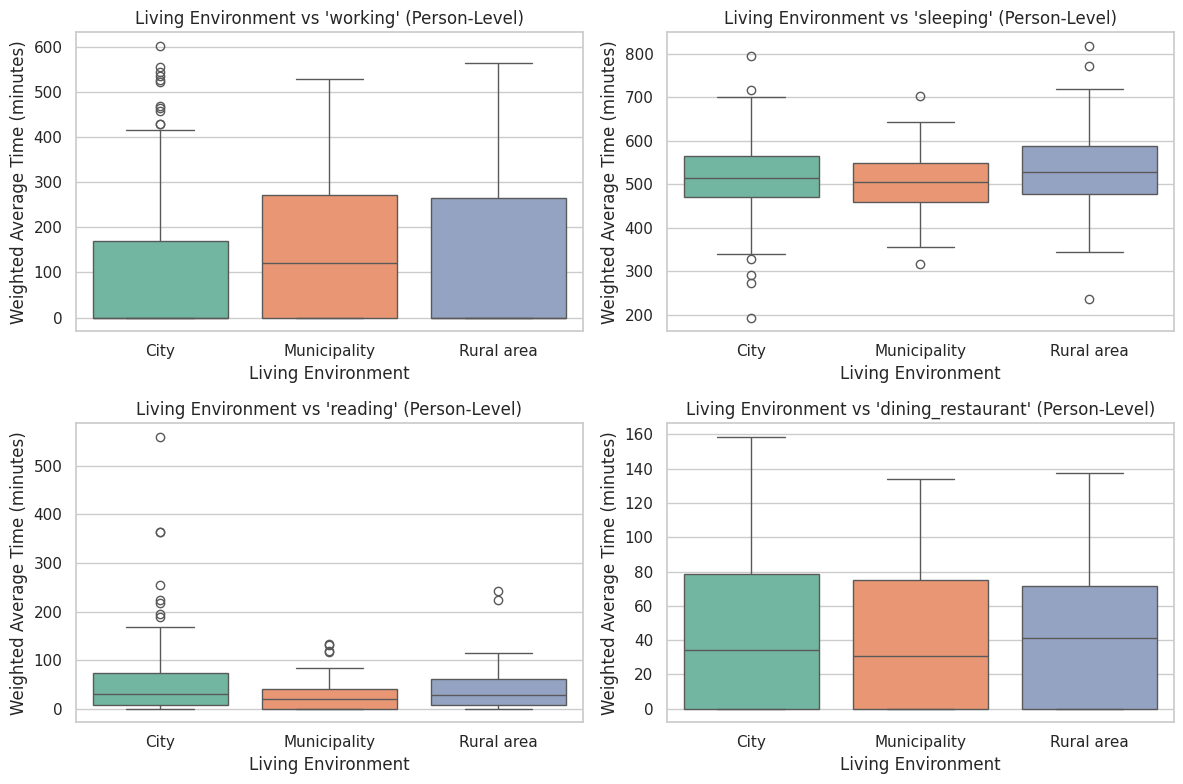

Independent Group Results (Living Environment, Person-Level):


,activity,test_applied,n,statistic,p_value,p_fdr,significant_fdr
0,working,Kruskal-Wallis,363,2.2569,0.3235,0.4314,False
1,sleeping,Kruskal-Wallis,359,3.8219,0.1479,0.2959,False
2,reading,Kruskal-Wallis,355,6.4346,0.0401,0.1603,False
3,dining_restaurant,Kruskal-Wallis,359,1.4420,0.4863,0.4863,False


In [34]:

# 1. Robustly aggregate 'living_environment' at the person level
person_env = (
    df_clean.groupby(["household_id", "member_id"], observed=True)[
        "living_environment"
    ]
    .apply(lambda x: x.dropna().iloc[0] if not x.dropna().empty else np.nan)
)

# 2. Weighted daily average at the person level (ensuring independence)
wide = (
    df_clean.set_index(["household_id", "member_id", "day_type"])[
        activity_columns
    ]
    .unstack("day_type")
)

person_means = pd.DataFrame({
    a: (5 / 7) * wide[(a, "Working day")] + (2 / 7) * wide[(a, "Weekend")]
    for a in activity_columns
}).join(person_env)

# People missing one of their two days get NaN here and are left out for that activity
# 3. Statistical pipeline: Normality check + Test selection (ANOVA / Kruskal) + FDR correction
env_results = []

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes = axes.flatten()

for idx, activity in enumerate(activity_columns):
  ax = axes[idx]
  if activity in person_means.columns:
    d = person_means[[activity, "living_environment"]].dropna()

    # Visualization (Person-level boxplot)
    sns.boxplot(
        data=d, x="living_environment", y=activity, hue="living_environment", legend=False, ax=ax, palette="Set2"
    )
    ax.set_title(f"Living Environment vs '{activity}' (Person-Level)")
    ax.set_xlabel("Living Environment")
    ax.set_ylabel("Weighted Average Time (minutes)")

    groups = [
        group[activity]
        for _, group in d.groupby("living_environment", observed=True)
    ]

    if len(groups) > 1:
      # Shapiro-Wilk normality test per group
      group_normals = [stats.shapiro(g)[1] > 0.05 for g in groups if len(g) >= 3]
      all_normal = all(group_normals) if group_normals else False

      # Automatic test selection
      if all_normal:
        stat, p_val = stats.f_oneway(*groups)
        test_used = "ANOVA"
      else:
        stat, p_val = stats.kruskal(*groups)
        test_used = "Kruskal-Wallis"

      env_results.append({
          "activity": activity,
          "test_applied": test_used,
          "n": len(d),
          "statistic": stat,
          "p_value": p_val,
      })

plt.tight_layout()
plt.show()

# Summary table with False Discovery Rate (FDR) control
df_env_summary = pd.DataFrame(env_results)
if not df_env_summary.empty:
  df_env_summary["p_fdr"] = stats.false_discovery_control(
      df_env_summary["p_value"]
  )
  df_env_summary["significant_fdr"] = df_env_summary["p_fdr"] < 0.05

print("Independent Group Results (Living Environment, Person-Level):")
display(df_env_summary.round(4))

**Interpretation**:

* **Plots:** The boxplots show different shapes across groups. *Sleeping* looks fairly balanced and symmetric, while *working* and *reading* are skewed. Normality is checked in all three groups at once, so a single group with heavy tails is enough to reject it. For that reason the **Kruskal-Wallis test** is used for all four activities.

* **Test results:** After FDR correction, **none** of the activities differ significantly across living environments (`significant_fdr = False` for all). *Reading* has a raw $p$-value of $0.0401$, but it is not significant after correction ($p_{fdr} \approx 0.160$). The others are clearly not significant either: `working` ($p_{fdr} \approx 0.43$), `sleeping` ($p_{fdr} \approx 0.30$) and `dining_restaurant` ($p_{fdr} \approx 0.49$).

* **Conclusion:** We fail to reject $H_0$. There is not enough evidence that time spent on each activity differs by living environment. This does not prove that there is no difference, only that this sample cannot show one.

### **4.2 Statistical Testing for Activity 5 (`library_visit`)**

Activity 5 (`library_visit`) is a yes/no variable, not a time in minutes. To test whether library-visiting habits differ across **living environments**, we use **Pearson's Chi-squared test of independence**.

- **Null Hypothesis ($H_0$):** Library visits are independent of the living environment.
- **Alternative Hypothesis ($H_1$):** There is an association between library visits and the living environment.

`library_visit` is a person-level attribute, so this test uses one row per person and not one row per diary day. We also do not test it against `day_type`: a person's 12-month library answer is the same on both of their rows, so that comparison would just compare a variable with a copy of itself.

In [35]:
# person-level A5, and only the living-environment test (the day_type
# test is removed, see note above)
from scipy import stats

person_a5 = (
    df_clean.groupby(["household_id", "member_id"], observed=True)
    .agg({
        "library_visit": lambda x: (
            x.dropna().iloc[0] if not x.dropna().empty else np.nan
        ),
        "living_environment": lambda x: (
            x.dropna().iloc[0] if not x.dropna().empty else np.nan
        ),
    })
    .reset_index()
)

print("Library Visits vs Living Environment (person-level)")
contingency_env = pd.crosstab(person_a5['living_environment'], person_a5['library_visit'])
display(contingency_env)

chi2_env, p_env, dof_env, ex_env = stats.chi2_contingency(contingency_env)
print(f"Chi2 Statistic: {chi2_env:.3f}, p-value: {p_env:.4f}")
print(f"Significant at alpha=0.05 (raw, uncorrected): {p_env < 0.05}")


Library Visits vs Living Environment (person-level)


library_visit,No,Yes
living_environment,,
City,61,156
Municipality,17,40
Rural area,31,44


Chi2 Statistic: 4.600, p-value: 0.1003
Significant at alpha=0.05 (raw, uncorrected): False


**Interpretation**: The Pearson's Chi-squared test gives $\chi^2 = 4.600$ with a $p$-value of $0.1003$. The $p$-value is above $0.05$, so we fail to reject $H_0$: there is no statistically significant association between library visits and living environment (City, Municipality, Rural area).

The shares of "Yes" are about 72% in cities (156 of 217), 70% in municipalities (40 of 57) and 59% in rural areas (44 of 75). Rural areas look lower, but with these sample sizes the gap is not large enough to rule out chance.

The test assumes that expected counts are not too small. The smallest expected count is about 17.8 (Municipality and "No": 57 x 109 / 349), well above the usual minimum of 5, so the test is appropriate.

### **Step 4 Recap**

- **Day of the week:** Reading and dining out are higher on weekends. Working and sleeping do not differ significantly between the two day types.
- **Working time:** Working days and weekends show roughly the same mean for working hours (about 122 minutes). We link this to the mixed make-up of the sample, but we could not test it.
- **Living environment:** No activity differs significantly across city, municipality and rural area after FDR correction.
- **Library visits:** They are not significantly linked to living environment (p = 0.10).

---
# **STEP 5: Statistical association between activities**

**Research Question:** Which activities are associated with each other? (Question 4)

To test the association between the continuous activities (`working`, `sleeping`, `reading` and `dining_restaurant`) we first define $H_0$.

- **Definition of $H_0$:** For a given pair of activities, there is no monotonic association between the time spent on them (Spearman's rank correlation $\rho = 0$).
- **Decision Rule:** If the FDR-adjusted $p$-value is less than $0.05$, we reject $H_0$ and conclude that the two activities are associated. If $p_{fdr} \ge 0.05$, we fail to reject $H_0$, which means there is not enough evidence of an association.

### **5.1 Association between the continuous activities (A1 to A4)**

Each person has two entries (a working day and a weekend day), so we separate the data by `day_type`. This gives one row per person in each analysis, so the observations are independent, and it lets us see the relationships inside each context.

We use Spearman's rank correlation instead of Pearson because the time-use data is skewed and zero-inflated (many people report 0 minutes), and Spearman is robust to skew and outliers. With 4 activities there are 6 pairs per day type, so we apply the FDR correction to those 6 tests. Many people share the same value (0 minutes), and Spearman handles these ties with average ranks.

--Day Type: Weekend (Complete cases: 352 of 368)--
Spearman Correlation Matrix:


/tmp/ipykernel_2822/2704895285.py:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for day_type_val, subset in df_clean.groupby('day_type'):


,working,sleeping,reading,dining_restaurant
working,1.000,-0.422,-0.217,0.025
sleeping,-0.422,1.000,-0.009,0.006
reading,-0.217,-0.009,1.000,-0.095
dining_restaurant,0.025,0.006,-0.095,1.000


P-value Matrix:


,working,sleeping,reading,dining_restaurant
working,0.0000,0.0000,0.0000,0.6433
sleeping,0.0000,0.0000,0.8642,0.9034
reading,0.0000,0.8642,0.0000,0.0737
dining_restaurant,0.6433,0.9034,0.0737,0.0000


Pairwise Correlations & FDR-adjusted P-values:


,pair,rho,p_value,p_fdr,significant_fdr
0,working vs sleeping,-0.4225,0.0000,0.0000,True
1,working vs reading,-0.2168,0.0000,0.0001,True
2,working vs dining_restaurant,0.0248,0.6433,0.9034,False
3,sleeping vs reading,-0.0091,0.8642,0.9034,False
4,sleeping vs dining_restaurant,0.0065,0.9034,0.9034,False
5,reading vs dining_restaurant,-0.0954,0.0737,0.1474,False


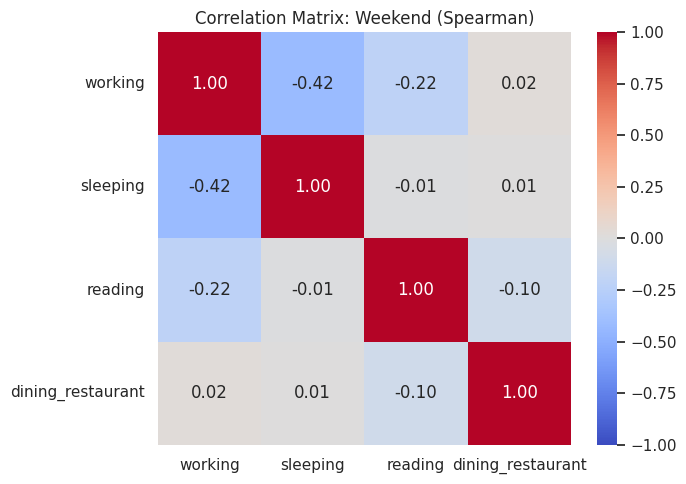

--Day Type: Working day (Complete cases: 360 of 377)--
Spearman Correlation Matrix:


,working,sleeping,reading,dining_restaurant
working,1.000,-0.377,-0.164,-0.069
sleeping,-0.377,1.000,0.016,0.055
reading,-0.164,0.016,1.000,-0.018
dining_restaurant,-0.069,0.055,-0.018,1.000


P-value Matrix:


,working,sleeping,reading,dining_restaurant
working,0.0000,0.0000,0.0018,0.1937
sleeping,0.0000,0.0000,0.7567,0.2996
reading,0.0018,0.7567,0.0000,0.7316
dining_restaurant,0.1937,0.2996,0.7316,0.0000


Pairwise Correlations & FDR-adjusted P-values:


,pair,rho,p_value,p_fdr,significant_fdr
0,working vs sleeping,-0.3768,0.0000,0.0000,True
1,working vs reading,-0.1642,0.0018,0.0053,True
2,working vs dining_restaurant,-0.0687,0.1937,0.3874,False
3,sleeping vs reading,0.0164,0.7567,0.7567,False
4,sleeping vs dining_restaurant,0.0548,0.2996,0.4494,False
5,reading vs dining_restaurant,-0.0181,0.7316,0.7567,False


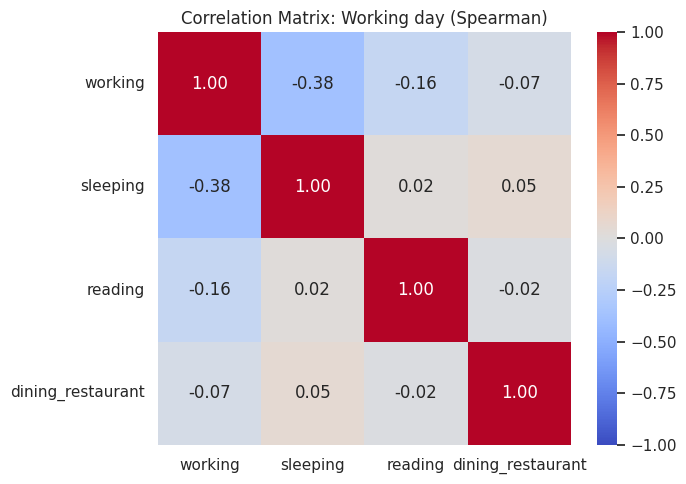

In [36]:
import itertools

# Step 5: Spearman Correlation Matrices Separated by Day Type

assoc_cols = ["working", "sleeping", "reading", "dining_restaurant"]

# Iterar separando por tipo de día (Working day vs. Weekend)
for day_type_val, subset in df_clean.groupby('day_type'):
    # Filtrar casos completos para las variables continuas en este subconjunto
    df_subset = subset[assoc_cols].dropna()
    print(f"--Day Type: {day_type_val} (Complete cases: {len(df_subset)} of {len(subset)})--")


    # Inicializar dataframes para coeficientes y p-values
    corr_matrix = pd.DataFrame(index=assoc_cols, columns=assoc_cols)
    pval_matrix = pd.DataFrame(index=assoc_cols, columns=assoc_cols)

    for col1 in assoc_cols:
        for col2 in assoc_cols:
            corr, pval = stats.spearmanr(df_subset[col1], df_subset[col2])
            corr_matrix.loc[col1, col2] = corr
            pval_matrix.loc[col1, col2] = pval

    corr_matrix = corr_matrix.astype(float)
    pval_matrix = pval_matrix.astype(float)

    print("Spearman Correlation Matrix:")
    display(corr_matrix.round(3))

    print("P-value Matrix:")
    display(pval_matrix.round(4))

    # FDR
    pairs = list(itertools.combinations(assoc_cols, 2))
    pair_table = pd.DataFrame({
        "pair": [f"{a} vs {b}" for a, b in pairs],
        "rho": [corr_matrix.loc[a, b] for a, b in pairs],
        "p_value": [pval_matrix.loc[a, b] for a, b in pairs],
    })
    pair_table["p_fdr"] = stats.false_discovery_control(pair_table["p_value"])
    pair_table["significant_fdr"] = pair_table["p_fdr"] < 0.05

    print("Pairwise Correlations & FDR-adjusted P-values:")
    display(pair_table.round(4))

    # Heatmap visual para cada tipo de día
    plt.figure(figsize=(7, 5))
    sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f")
    plt.title(f"Correlation Matrix: {day_type_val} (Spearman)")
    plt.tight_layout()
    plt.show()

**Note:** While the initial EDA provided a descriptive overview of overall patterns, this section performs formal hypothesis testing using Spearman's rank correlationseparated by day type. This allows us to
evaluate whether activity relationships are statistically significant.


**Interpretation**:

* **Results:** After FDR correction, two relationships are significant on both day types. The strongest is between **working** and **sleeping**, a moderate negative correlation on weekends ($\rho = -0.422$, $p_{\text{fdr}} < 0.001$) and on working days ($\rho = -0.378$, $p_{\text{fdr}} < 0.001$). The second is a weak negative correlation between **working** and **reading** on weekends ($\rho = -0.217$, $p_{\text{fdr}} \approx 0.0001$) and working days ($\rho = -0.164$, $p_{\text{fdr}} \approx 0.0053$).

* **Conclusion:** People who spend more time working tend to sleep less and read less. This fits the idea that people have a limited amount of time in a day. The correlation does not show that work causes the lower sleep or reading time. All other pairs are not significant after correction.

### **5.2 Association between library visits (A5) and continuous activities (A1 to A4)**

**Method.**
- A5 is asked once per person, but the diary has two rows per person. To avoid counting people twice, we use one row per person.
- For each activity, the two diary days are combined into one daily average: 5/7 of the working day value plus 2/7 of the weekend value. People missing one of the two days are left out for that activity.
- For A5 we take the first valid answer of each person, because the answer can be missing in one row and valid in the other. It is coded as 1 for Yes and 0 for No.
- To see whether time spent on an activity differs between people who visited a library and people who did not, we compare a continuous variable across two independent groups. The data is skewed and zero-inflated, so we use the non-parametric **Mann-Whitney U test** (unpaired). The 4 tests are corrected together with FDR.

People with a valid library answer: 349
{'Yes': 240, 'No': 109}


,activity,n,median_yes,median_no,p_value,p_fdr,significant_fdr
0,working,335,14.286,0.000,0.111,0.442,False
1,sleeping,330,512.857,514.286,0.814,0.906,False
2,reading,329,28.571,27.429,0.701,0.906,False
3,dining_restaurant,331,34.286,34.286,0.906,0.906,False


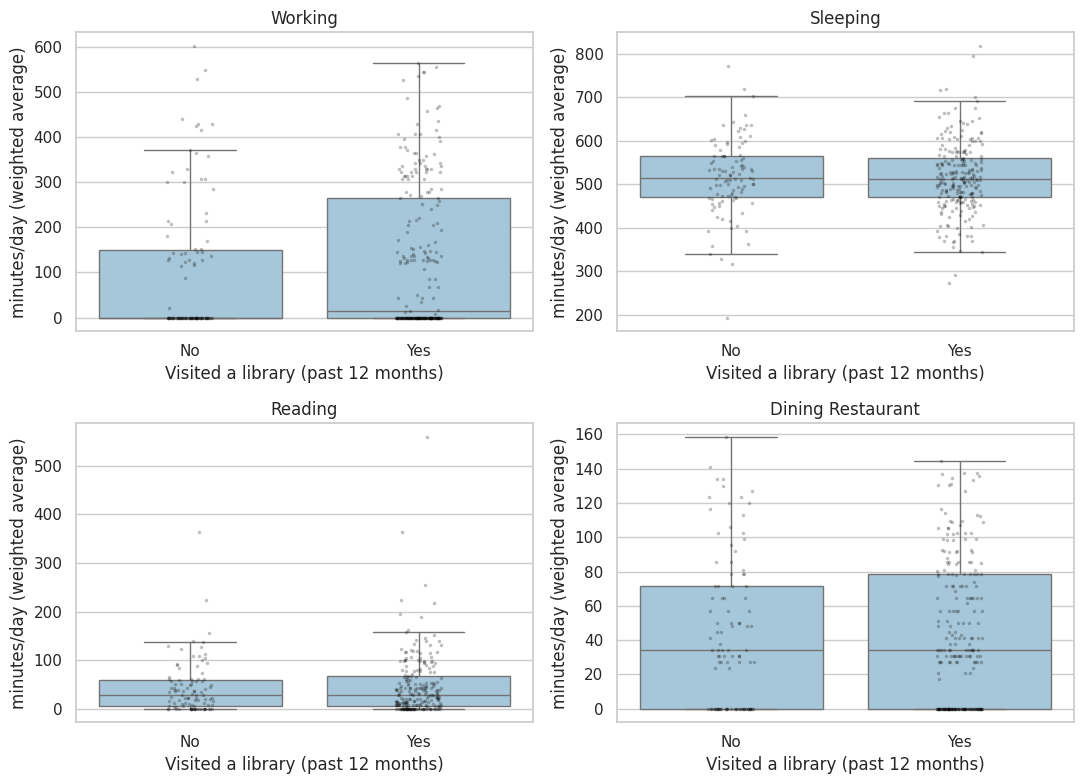

In [37]:
# 5.2 Library visits (A5) vs continuous activities (A1 to A4)

activities = ["working", "sleeping", "reading", "dining_restaurant"]
person_id = ["household_id", "member_id"]

# 1) Library answer: one value per person (first valid answer, not first row)
library_person = df_clean.groupby(person_id, observed=True)["library_visit"].first()

# 2) Weighted daily average per person: 5/7 working day + 2/7 weekend
wide = df_clean.set_index(person_id + ["day_type"])[activities].unstack("day_type")
person_means = pd.DataFrame({
    act: (5/7) * wide[(act, "Working day")] + (2/7) * wide[(act, "Weekend")]
    for act in activities
})

# 3) One table, one row per person, keep valid library answers only
person_df = person_means.join(library_person).dropna(subset=["library_visit"])
person_df["library_bin"] = (person_df["library_visit"] == "Yes").astype(int)  # 1 = Yes, 0 = No

print("People with a valid library answer:", len(person_df))
print(person_df["library_visit"].value_counts().to_dict())

# 4) Mann-Whitney U test (unpaired, non-parametric)
rows = []
for act in activities:
    d = person_df[[act, "library_bin"]].dropna()
    yes = d.loc[d["library_bin"] == 1, act]
    no = d.loc[d["library_bin"] == 0, act]

    u, p = stats.mannwhitneyu(yes, no, alternative="two-sided")

    rows.append({
        "activity": act,
        "n": len(d),
        "median_yes": yes.median(),
        "median_no": no.median(),
        "p_value": p
    })

results_52 = pd.DataFrame(rows)
results_52["p_fdr"] = stats.false_discovery_control(results_52["p_value"])
results_52["significant_fdr"] = results_52["p_fdr"] < 0.05
display(results_52.round(3))

# 6) Boxplots with individual points
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for ax, act in zip(axes.ravel(), activities):
    sns.boxplot(data=person_df, x="library_visit", y=act, order=["No", "Yes"],
                color="#9ecae1", showfliers=False, ax=ax)
    sns.stripplot(data=person_df, x="library_visit", y=act, order=["No", "Yes"],
                  color="black", alpha=0.25, size=2.5, ax=ax)
    ax.set_title(act.replace("_", " ").title())
    ax.set_xlabel("Visited a library (past 12 months)")
    ax.set_ylabel("minutes/day (weighted average)")
plt.tight_layout()
plt.show()

**Interpretation**:

* **Test results:** After FDR correction across the four activities, **none** of them (**working**, **sleeping**, **reading**, **dining_restaurant**) differs significantly between people who visited a library and people who did not (`significant_fdr = False` for all).
* All adjusted $p$-values are well above $0.05$ (from $0.442$ for working to $0.906$ for sleeping, reading and dining out). Working shows a small gap in the medians (14.3 vs 0 minutes), but it is not significant after correction. So library use is not linked to these daily activities in this sample.

### **Step 5 Recap**

- **Pairs of activities:** Working is negatively linked to sleeping (moderate) and to reading (weak), on both working days and weekends.
- **Other pairs:** Reading, sleeping and dining out are not significantly linked to each other.
- **Library visits:** Whether a person visited a library is not significantly linked to any of the four activities.

# **FINAL CONCLUSIONS**

---

This section answers the four questions of the brief in short form. Each answer points to the step where the evidence is.

### **Question 1: Who are the individuals in the data?**
The data has 378 people, each living in a different household. They are all adults aged 20 to 84, almost balanced by sex (51.9% women), and most live in cities (63.5%). About 19% are 65 or older. Every person has up to two diary days, one working day and one weekend day (Steps 0 to 2).


### **Question 2: How much time do households spend on each activity per day?**
On an average day, households spend about 8.6 hours sleeping, about 45 to 56 minutes reading, about 41 to 56 minutes dining at a restaurant, and about 2 hours working (122 minutes). The working average is only a mean: more than half of the days have no work at all. Working days and weekends show roughly the same mean for working hours. In our interpretation, this comes from the mixed make-up of the sample (retirees, students, and self-employed people or shift workers with flexible schedules), but we could not test this. About 69% of people visited a library in the past year (Step 3).

### **Question 3: With respect to which activities do living environments or days of the week differ?**
**Day of the week:** reading and dining out are higher on weekends, and the difference is significant after FDR correction. Sleeping and working do not differ significantly between day types.

**Living environment:** none of the four activities differs significantly between city, municipality and rural area, and library visits are not significantly linked to living environment either. Not finding a difference does not prove there is none, only that this sample cannot show one (Step 4).

### **Question 4: Which activities are associated with each other?**
Working is the activity that is linked to the others. People who work more tend to sleep less (moderate link, about -0.38 to -0.42) and to read less (weak link, about -0.16 to -0.22), on both working days and weekends. Dining out is not significantly linked to any other activity, and neither are reading and sleeping. The PCA shows the same picture: the first component is a work versus sleep axis, and two components explain only about 62.5% of the variance, so the links are not strong. Library visits are not linked to any of the four activities (Steps 2 and 5).